# Sprint 2 – Machine Learning Model Development
## Predicting review sentiment / rating from review text

**Input:** `cleaned_reviews.csv` (produced by `EDA and Feature Engineering.ipynb`)

**Plan**
1. Configuration & data preparation
2. Train/test split (stratified)
3. Text vectorisation: Bag of Words vs TF-IDF
4. Train 6 algorithms × 2 vectorisers = 12 models
5. Evaluate: accuracy, precision, recall, F1, confusion matrix, classification report
6. Compare all models (tables and charts)
7. Optional hyper-parameter tuning of Logistic Regression
8. Interpret the best model, save it, and predict on new text

### Metrics used
| Metric | Meaning |
|---|---|
| **Accuracy** | share of all predictions that are correct |
| **Precision** | of the reviews predicted as class *X*, how many really are *X* |
| **Recall** | of the reviews that really are *X*, how many we found |
| **F1-score** | harmonic mean of precision and recall |
| **Macro average** | average over classes, every class counts equally |
| **Weighted average** | average over classes, weighted by class size |

Because the data is heavily skewed toward positive reviews, **macro-F1 is the main comparison metric**.
Accuracy alone is misleading: always predicting "Positive" already gives a high accuracy.

## 1. Configuration & Setup

In [1]:
import re, html, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.4f}".format

# ------------------------------- CONFIGURATION -------------------------------
TARGET       = "Sentiment"   # "Sentiment": Negative/Neutral/Positive (3 classes)
                             # "Score"    : exact star rating 1-5 (5 classes, much harder)
                             # "Binary"   : Negative vs Positive (neutral reviews dropped)
SAMPLE_SIZE  = 60_000        # stratified sample so KNN / Random Forest finish in reasonable time; None = all rows
TEST_SIZE    = 0.20
RANDOM_STATE = 42
MAX_FEATURES = 5_000         # vocabulary size per vectoriser
NGRAM_RANGE  = (1, 2)        # unigrams + bigrams (captures "not good", "highly recommend")
RUN_TUNING   = True          # grid search for Logistic Regression (section 7)
# -----------------------------------------------------------------------------

**Why a sample?** The full cleaned dataset has ~390k reviews. K-Nearest Neighbours compares every test review
with every training review, and Random Forest builds 100 trees, so both become very slow at that size.
A stratified sample keeps the class proportions and gives results close to the full data. Set
`SAMPLE_SIZE = None` to train on everything (expect a long run).

## 2. Data Preparation

In [2]:
df = pd.read_csv("cleaned_reviews.csv", usecols=["Score", "Sentiment", "CleanText"])
df = df.dropna(subset=["CleanText"])
df = df[df["CleanText"].str.strip() != ""]
print("Loaded rows:", f"{len(df):,}")

# ---- choose the prediction target
if TARGET == "Binary":
    df = df[df["Sentiment"] != "Neutral"].copy()
    target_col, labels = "Sentiment", ["Negative", "Positive"]
elif TARGET == "Sentiment":
    target_col, labels = "Sentiment", ["Negative", "Neutral", "Positive"]
elif TARGET == "Score":
    target_col, labels = "Score", [1, 2, 3, 4, 5]
else:
    raise ValueError("TARGET must be 'Sentiment', 'Score' or 'Binary'")

# ---- stratified sample (keeps class proportions)
if SAMPLE_SIZE and len(df) > SAMPLE_SIZE:
    df, _ = train_test_split(df, train_size=SAMPLE_SIZE, stratify=df[target_col], random_state=RANDOM_STATE)
df = df.reset_index(drop=True)

print(f"Target: {TARGET}  |  classes: {labels}  |  rows used: {len(df):,}")
dist = df[target_col].value_counts().reindex(labels)
display(pd.DataFrame({"count": dist, "percent": dist / dist.sum() * 100}))

Loaded rows: 393,883


Target: Sentiment  |  classes: ['Negative', 'Neutral', 'Positive']  |  rows used: 60,000


,count,percent
Sentiment,,
Negative,8698,14.4967
Neutral,4535,7.5583
Positive,46767,77.9450


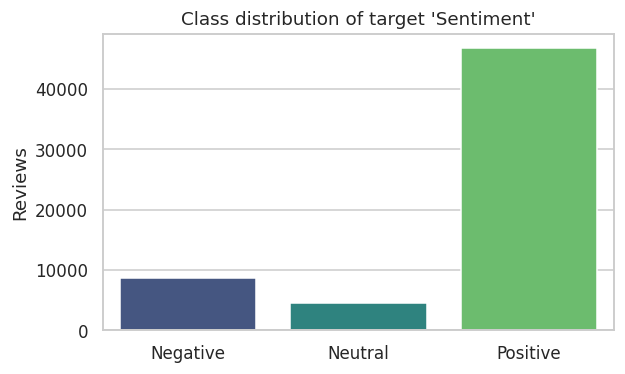

OBSERVATIONS
- The majority class is 'Positive' with 77.9% of the data.
- A useless model that always predicts 'Positive' already reaches 77.9% accuracy.
  Any real model must be judged against this baseline, and with macro-F1 rather than accuracy alone.


In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=[str(l) for l in dist.index], y=dist.values, palette="viridis", ax=ax)
ax.set(title=f"Class distribution of target '{TARGET}'", xlabel="", ylabel="Reviews")
plt.show()

baseline = dist.max() / dist.sum()
print("OBSERVATIONS")
print(f"- The majority class is '{dist.idxmax()}' with {baseline:.1%} of the data.")
print(f"- A useless model that always predicts '{dist.idxmax()}' already reaches {baseline:.1%} accuracy.")
print("  Any real model must be judged against this baseline, and with macro-F1 rather than accuracy alone.")

## 3. Train / Test Split
The split is **stratified** so that train and test keep the same class proportions.
Vectorisers are fitted on the **training set only**; fitting on all data would leak test vocabulary into training.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["CleanText"], df[target_col],
    test_size=TEST_SIZE, stratify=df[target_col], random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")
display(pd.DataFrame({"train_%": y_train.value_counts(normalize=True).reindex(labels) * 100,
                      "test_%":  y_test.value_counts(normalize=True).reindex(labels) * 100}))

Train: 48,000   Test: 12,000


,train_%,test_%
Sentiment,,
Negative,14.4958,14.5000
Neutral,7.5583,7.5583
Positive,77.9458,77.9417


## 4. Feature Engineering – Text Vectorisation

Machine-learning models need numbers, not words. Two classic techniques:

| Technique | How a review becomes a vector |
|---|---|
| **Bag of Words** (`CountVectorizer`) | one column per word/bigram; the value is **how many times** it appears |
| **TF-IDF** (`TfidfVectorizer`) | same columns, but counts are **re-weighted**: words common to almost every review get low weight, distinctive words get high weight |

Settings (both): top `MAX_FEATURES` terms, unigrams + bigrams, `min_df=3` (ignore terms appearing in fewer than 3 reviews).
TF-IDF additionally uses `sublinear_tf=True` (log-scaled counts so a word repeated 20 times does not dominate).

In [5]:
vectorizers = {
    "BoW":    CountVectorizer(max_features=MAX_FEATURES, ngram_range=NGRAM_RANGE, min_df=3),
    "TF-IDF": TfidfVectorizer(max_features=MAX_FEATURES, ngram_range=NGRAM_RANGE, min_df=3, sublinear_tf=True),
}

Xtr, Xte = {}, {}
for name, vec in vectorizers.items():
    Xtr[name] = vec.fit_transform(X_train)     # fit on TRAIN only
    Xte[name] = vec.transform(X_test)          # transform test with the train vocabulary
    sparsity = 1 - Xtr[name].nnz / (Xtr[name].shape[0] * Xtr[name].shape[1])
    print(f"{name:7s} matrix: {Xtr[name].shape}  |  {sparsity:.2%} zeros")

BoW     matrix: (48000, 5000)  |  99.28% zeros


TF-IDF  matrix: (48000, 5000)  |  99.28% zeros


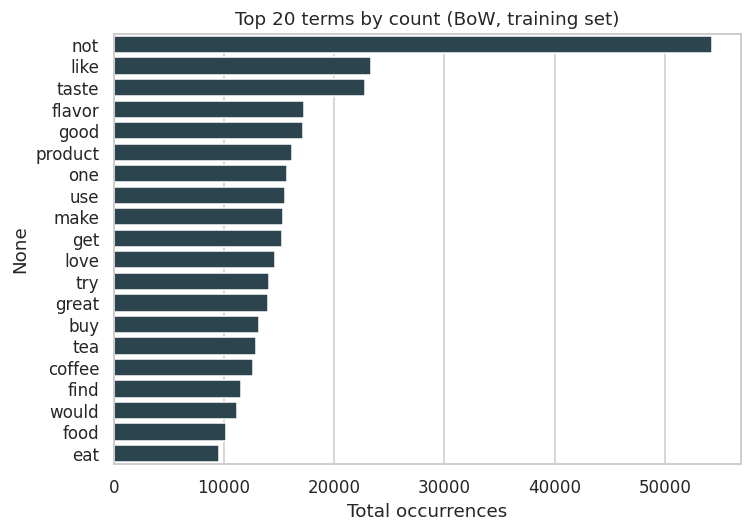

OBSERVATIONS
- Each matrix has 5,000 columns, and almost every cell is zero: reviews use only a handful of the vocabulary.
  Sparse matrices keep this memory-efficient.
- The most frequent terms include generic domain words (taste, flavor, product). BoW weights them heavily;
  TF-IDF shrinks their influence, which often helps linear models.


In [6]:
terms = np.array(vectorizers["BoW"].get_feature_names_out())
tot = np.asarray(Xtr["BoW"].sum(axis=0)).ravel()
top = pd.Series(tot, index=terms).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=top.values, y=top.index, color="#264653", ax=ax)
ax.set(title="Top 20 terms by count (BoW, training set)", xlabel="Total occurrences")
plt.tight_layout(); plt.show()

print("OBSERVATIONS")
print(f"- Each matrix has {MAX_FEATURES:,} columns, and almost every cell is zero: reviews use only a handful of the vocabulary.")
print("  Sparse matrices keep this memory-efficient.")
print("- The most frequent terms include generic domain words (taste, flavor, product). BoW weights them heavily;")
print("  TF-IDF shrinks their influence, which often helps linear models.")

## 5. Model Training & Evaluation

| Model | Notes / settings |
|---|---|
| **Naive Bayes** | `MultinomialNB`; classic fast baseline for word counts |
| **Logistic Regression** | `class_weight="balanced"` so rare classes are not ignored |
| **SVM** | `LinearSVC` (linear kernel). A kernel `SVC` is far too slow on thousands of text features; linear SVM is the standard choice for text |
| **Decision Tree** | `min_samples_leaf=5` to limit over-fitting, balanced class weights |
| **Random Forest** | 100 trees, balanced class weights, uses all CPU cores |
| **KNN** | `k=5`, cosine distance (the right similarity for text vectors), brute-force search |

Every model is trained with both vectorisers, giving 12 combinations.

In [7]:
def make_models():
    """Fresh, un-fitted instances (so each vectoriser gets its own models)."""
    return {
        "Naive Bayes":         MultinomialNB(),
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "SVM (Linear)":        LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
        "Decision Tree":       DecisionTreeClassifier(min_samples_leaf=5, class_weight="balanced",
                                                      random_state=RANDOM_STATE),
        "Random Forest":       RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                                                      class_weight="balanced_subsample",
                                                      n_jobs=-1, random_state=RANDOM_STATE),
        "KNN":                 KNeighborsClassifier(n_neighbors=5, metric="cosine",
                                                    algorithm="brute", n_jobs=-1),
    }

records, preds, reports, fitted = [], {}, {}, {}

def evaluate(vec_name, model_name, model, train_time):
    """Predict on the test set and store every metric for one fitted model."""
    t0 = time.time()
    y_pred = model.predict(Xte[vec_name])
    pred_time = time.time() - t0
    key = (vec_name, model_name)
    preds[key], fitted[key] = y_pred, model
    reports[key] = classification_report(y_test, y_pred, labels=labels,
                                         target_names=[str(l) for l in labels], zero_division=0)
    records.append({
        "Model": model_name, "Vectorizer": vec_name,
        "Accuracy":        accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)":        f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (weighted)":     f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Train time (s)": train_time, "Predict time (s)": pred_time,
    })

In [8]:
for vec_name in vectorizers:
    for model_name, model in make_models().items():
        t0 = time.time()
        model.fit(Xtr[vec_name], y_train)
        train_time = time.time() - t0
        evaluate(vec_name, model_name, model, train_time)
        r = records[-1]
        print(f"{vec_name:7s} | {model_name:20s} | acc={r['Accuracy']:.3f}  F1-macro={r['F1 (macro)']:.3f}  "
              f"train={train_time:6.1f}s")

BoW     | Naive Bayes          | acc=0.804  F1-macro=0.615  train=   0.1s


BoW     | Logistic Regression  | acc=0.773  F1-macro=0.588  train=   4.0s


BoW     | SVM (Linear)         | acc=0.815  F1-macro=0.608  train=  15.6s


BoW     | Decision Tree        | acc=0.613  F1-macro=0.449  train=  22.9s


BoW     | Random Forest        | acc=0.835  F1-macro=0.574  train=  75.8s


BoW     | KNN                  | acc=0.759  F1-macro=0.478  train=   0.1s


... (2 outputs left out)

TF-IDF  | SVM (Linear)         | acc=0.827  F1-macro=0.629  train=   1.2s


TF-IDF  | Decision Tree        | acc=0.632  F1-macro=0.458  train=  26.9s


TF-IDF  | Random Forest        | acc=0.834  F1-macro=0.544  train=  73.9s


TF-IDF  | KNN                  | acc=0.793  F1-macro=0.469  train=   0.1s


## 6. Comparing All Models

### 6.1 Results table (sorted by macro-F1)

In [9]:
results = pd.DataFrame(records).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
results.index += 1
display(results)

,Model,Vectorizer,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Train time (s),Predict time (s)
1,SVM (Linear),TF-IDF,0.8266,0.6176,0.6416,0.6286,0.8318,1.1618,0.0036
2,Logistic Regression,TF-IDF,0.7788,0.5962,0.6739,0.6163,0.8061,1.1493,0.0024
3,Naive Bayes,BoW,0.8040,0.5980,0.6403,0.6148,0.8158,0.0956,0.0026
4,SVM (Linear),BoW,0.8152,0.5990,0.6183,0.6078,0.8206,15.6388,0.0038
5,Logistic Regression,BoW,0.7727,0.5695,0.6279,0.5875,0.7957,3.9624,0.0026
6,Random Forest,BoW,0.8352,0.6385,0.5597,0.5740,0.8159,75.7986,0.4394
7,Random Forest,TF-IDF,0.8341,0.6468,0.5233,0.5436,0.8057,73.8901,0.4280
8,KNN,BoW,0.7586,0.4845,0.4776,0.4778,0.7487,0.0738,14.3359
9,KNN,TF-IDF,0.7933,0.5375,0.4518,0.4686,0.7592,0.0807,12.3939
10,Naive Bayes,TF-IDF,0.8252,0.7546,0.4458,0.4658,0.7735,0.1106,0.0035


### 6.2 Accuracy and macro-F1 by model and vectoriser

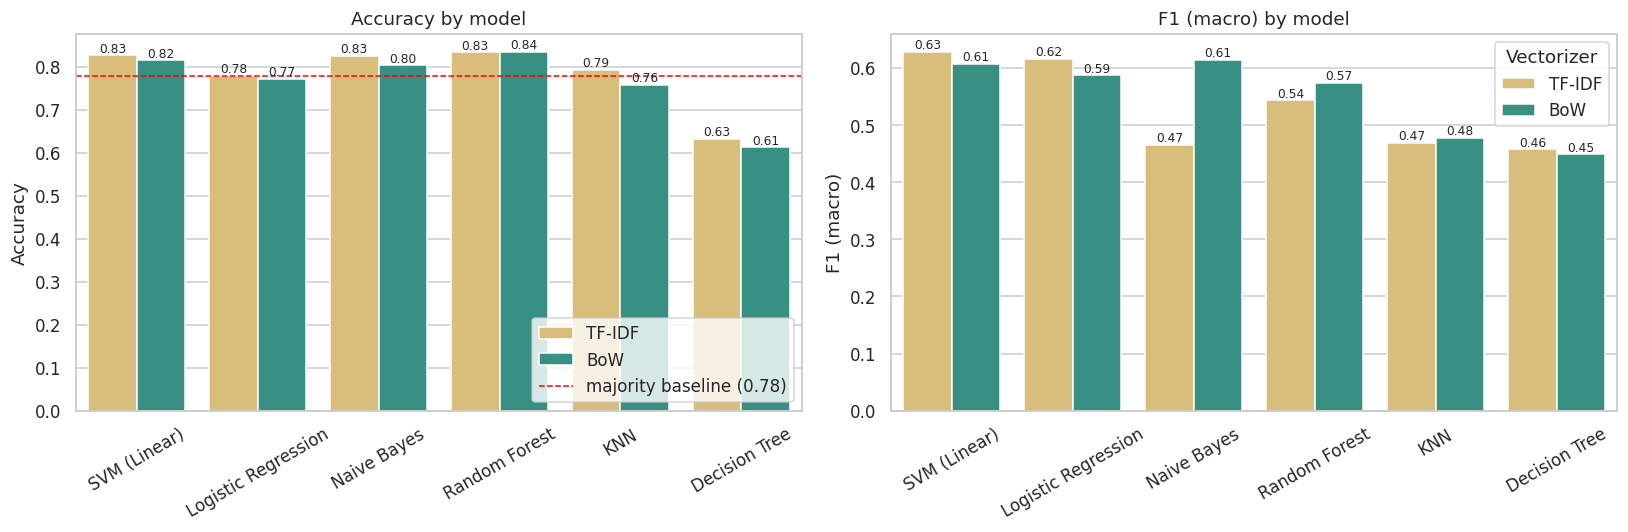

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = results.groupby("Model")["F1 (macro)"].max().sort_values(ascending=False).index
for ax, metric in zip(axes, ["Accuracy", "F1 (macro)"]):
    sns.barplot(data=results, x="Model", y=metric, hue="Vectorizer", order=order,
                palette=["#e9c46a", "#2a9d8f"], ax=ax)
    ax.set_title(f"{metric} by model"); ax.tick_params(axis="x", rotation=30); ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=8)
axes[0].axhline(baseline, color="red", ls="--", lw=1, label=f"majority baseline ({baseline:.2f})")
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

In [11]:
base = results[~results["Model"].str.contains("tuned")]
best = results.iloc[0]
worst = base.iloc[-1]
vec_mean = base.groupby("Vectorizer")["F1 (macro)"].mean()
gap = results.assign(gap=results["Accuracy"] - results["F1 (macro)"]).sort_values("gap", ascending=False).iloc[0]

print("OBSERVATIONS")
print(f"- Best model  : {best['Model']} + {best['Vectorizer']}  (macro-F1 {best['F1 (macro)']:.3f}, accuracy {best['Accuracy']:.3f}).")
print(f"- Weakest     : {worst['Model']} + {worst['Vectorizer']}  (macro-F1 {worst['F1 (macro)']:.3f}).")
print(f"- Average macro-F1 across models: " + ", ".join(f"{k} = {v:.3f}" for k, v in vec_mean.items()))
print(f"- Largest accuracy-vs-F1 gap: {gap['Model']} + {gap['Vectorizer']} (accuracy {gap['Accuracy']:.3f} vs macro-F1 {gap['F1 (macro)']:.3f}).")
print("  A big gap means the model scores well by favouring the majority class while doing poorly on minority classes.")
below = base[base["Accuracy"] < baseline]
print(f"- {len(below)} of {len(base)} combinations have accuracy below the majority baseline ({baseline:.3f}): "
      + (", ".join(f"{r.Model}+{r.Vectorizer}" for r in below.itertuples()) or "none") + ".")
print("  For class-weighted models (e.g. Logistic Regression) this is a deliberate trade: lower accuracy in exchange for finding more")
print("  minority-class reviews. For Decision Tree / KNN it simply reflects a weaker fit to sparse text.")
piv = base.pivot(index="Model", columns="Vectorizer", values="F1 (macro)")
d = (piv["TF-IDF"] - piv["BoW"]).sort_values()
print("- TF-IDF minus BoW (macro-F1) per model: " + ", ".join(f"{m} {v:+.3f}" for m, v in d.items()))
print("  TF-IDF helps the linear models, but Naive Bayes collapses with it: TF-IDF's small fractional weights make MultinomialNB lean")
print("  heavily toward the majority class (note its high precision but low recall in 6.3). BoW counts suit Naive Bayes better.")
acc_best = base.sort_values("Accuracy", ascending=False).iloc[0]
print(f"- Highest accuracy: {acc_best['Model']} + {acc_best['Vectorizer']} ({acc_best['Accuracy']:.3f}), but its macro-F1 is only {acc_best['F1 (macro)']:.3f}:")
print("  the accuracy winner and the macro-F1 winner are not the same model, which is why macro-F1 is the main metric here.")

OBSERVATIONS
- Best model  : SVM (Linear) + TF-IDF  (macro-F1 0.629, accuracy 0.827).
- Weakest     : Decision Tree + BoW  (macro-F1 0.449).
- Average macro-F1 across models: BoW = 0.552, TF-IDF = 0.530
- Largest accuracy-vs-F1 gap: Naive Bayes + TF-IDF (accuracy 0.825 vs macro-F1 0.466).
  A big gap means the model scores well by favouring the majority class while doing poorly on minority classes.
- 5 of 12 combinations have accuracy below the majority baseline (0.779): Logistic Regression+TF-IDF, Logistic Regression+BoW, KNN+BoW, Decision Tree+TF-IDF, Decision Tree+BoW.
  For class-weighted models (e.g. Logistic Regression) this is a deliberate trade: lower accuracy in exchange for finding more
  minority-class reviews. For Decision Tree / KNN it simply reflects a weaker fit to sparse text.
- TF-IDF minus BoW (macro-F1) per model: Naive Bayes -0.149, Random Forest -0.030, KNN -0.009, Decision Tree +0.009, SVM (Linear) +0.021, Logistic Regression +0.029
  TF-IDF helps the linear model

### 6.3 All metrics at a glance

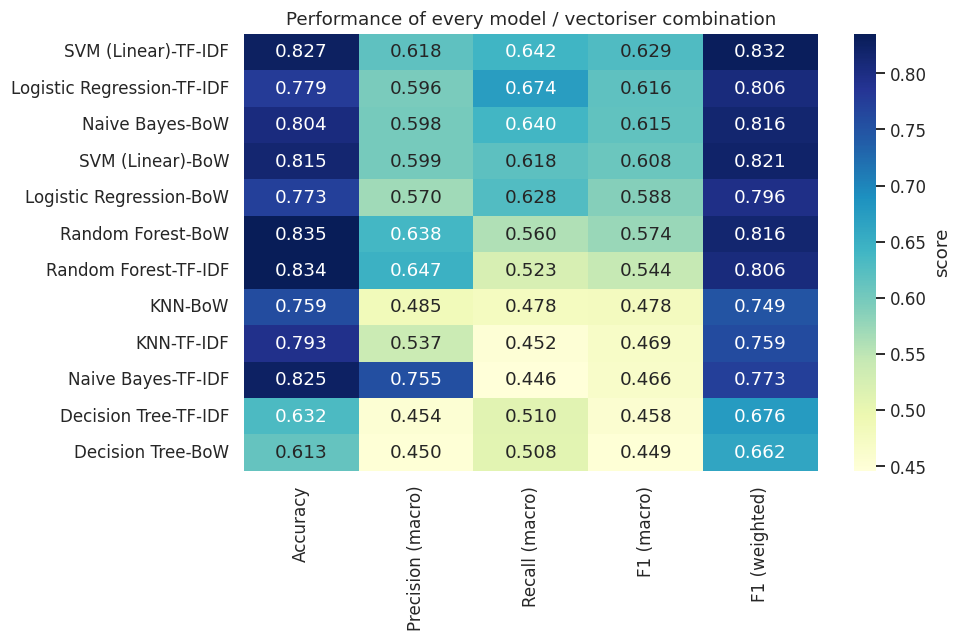

OBSERVATIONS
- Spread of macro-F1 between best and worst model: 0.180.
- Most precision-heavy (cautious) model: Naive Bayes + TF-IDF (precision 0.755 vs recall 0.446).
- Most recall-heavy model: Logistic Regression + TF-IDF (precision 0.596 vs recall 0.674).


In [12]:
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 (weighted)"]
hm = base.set_index(["Model", "Vectorizer"])[metric_cols].sort_values("F1 (macro)", ascending=False)
plt.figure(figsize=(9, 6))
sns.heatmap(hm, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "score"})
plt.title("Performance of every model / vectoriser combination"); plt.ylabel("")
plt.tight_layout(); plt.show()

print("OBSERVATIONS")
print(f"- Spread of macro-F1 between best and worst model: {hm['F1 (macro)'].max() - hm['F1 (macro)'].min():.3f}.")
pr = base.assign(d=base["Precision (macro)"] - base["Recall (macro)"])
hi_p = pr.sort_values("d", ascending=False).iloc[0]
print(f"- Most precision-heavy (cautious) model: {hi_p['Model']} + {hi_p['Vectorizer']} "
      f"(precision {hi_p['Precision (macro)']:.3f} vs recall {hi_p['Recall (macro)']:.3f}).")
lo_p = pr.sort_values("d").iloc[0]
print(f"- Most recall-heavy model: {lo_p['Model']} + {lo_p['Vectorizer']} "
      f"(precision {lo_p['Precision (macro)']:.3f} vs recall {lo_p['Recall (macro)']:.3f}).")

### 6.4 Training time vs performance

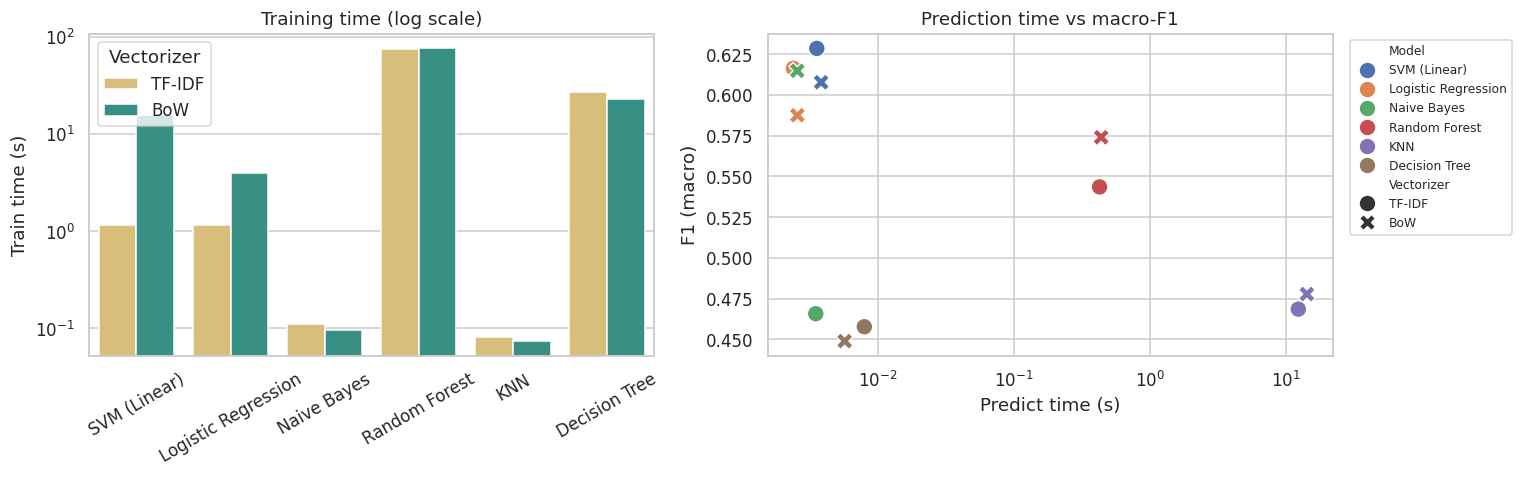

OBSERVATIONS
- Fastest to train: KNN (0.07s); slowest: Random Forest (75.8s).
- Slowest to predict: KNN (14.3s). KNN has no real training step; it stores the data and
  does all its work at prediction time, which is why it is impractical for large-scale deployment.
- Linear models (Naive Bayes, Logistic Regression, Linear SVM) are typically both fast and strong on sparse text.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=base, x="Model", y="Train time (s)", hue="Vectorizer", palette=["#e9c46a", "#2a9d8f"], ax=axes[0])
axes[0].set_yscale("log"); axes[0].tick_params(axis="x", rotation=30)
axes[0].set(title="Training time (log scale)", xlabel="")

sns.scatterplot(data=base, x="Predict time (s)", y="F1 (macro)", hue="Model", style="Vectorizer", s=120, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("Prediction time vs macro-F1")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

fast = base.sort_values("Train time (s)").iloc[0]
slow = base.sort_values("Train time (s)").iloc[-1]
pslow = base.sort_values("Predict time (s)").iloc[-1]
print("OBSERVATIONS")
print(f"- Fastest to train: {fast['Model']} ({fast['Train time (s)']:.2f}s); slowest: {slow['Model']} ({slow['Train time (s)']:.1f}s).")
print(f"- Slowest to predict: {pslow['Model']} ({pslow['Predict time (s)']:.1f}s). KNN has no real training step; it stores the data and")
print("  does all its work at prediction time, which is why it is impractical for large-scale deployment.")
print("- Linear models (Naive Bayes, Logistic Regression, Linear SVM) are typically both fast and strong on sparse text.")

### 6.5 Confusion matrices
Rows = true class, columns = predicted class. Values are **normalised per row**, so the diagonal shows the
**recall of each class** (e.g. 0.80 means 80% of the true reviews of that class were found).
Each model is shown with its better vectoriser.

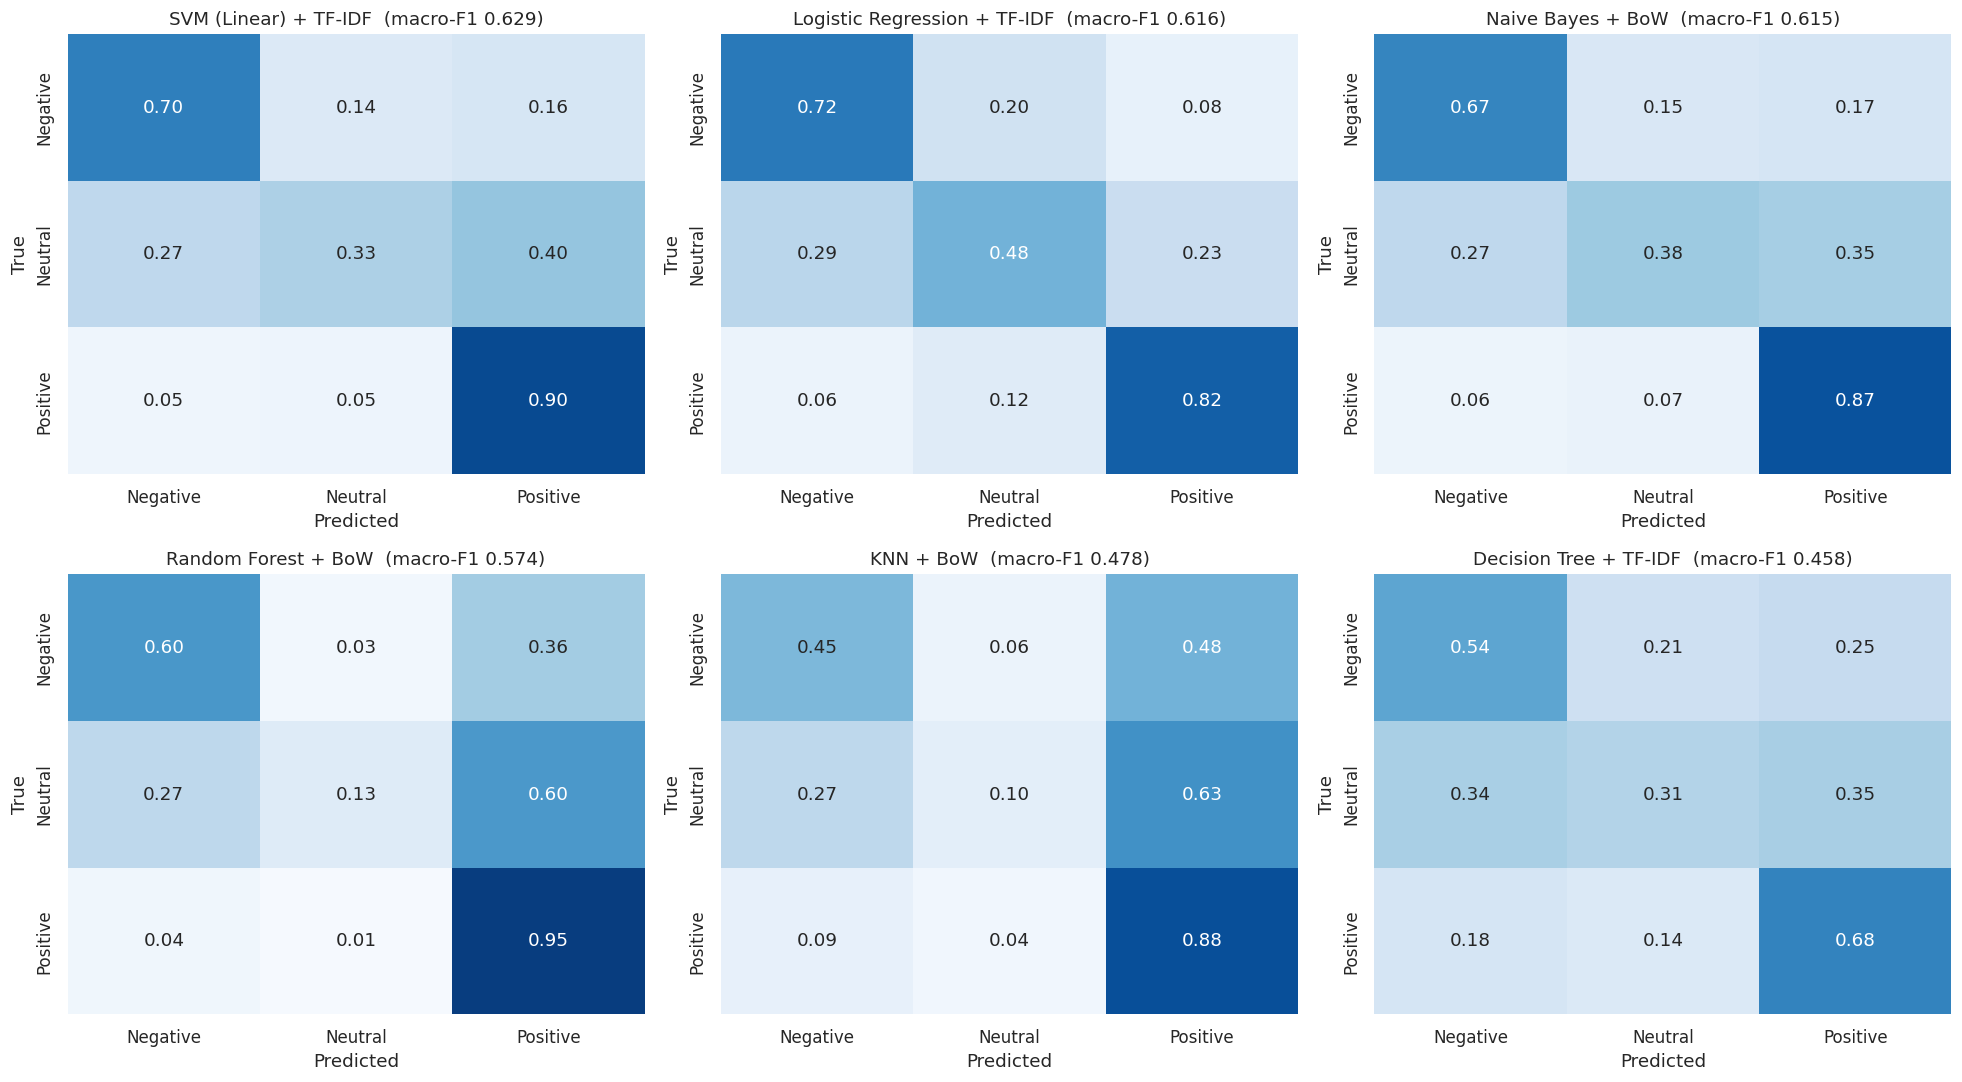

In [14]:
best_vec = base.sort_values("F1 (macro)", ascending=False).drop_duplicates("Model").set_index("Model")["Vectorizer"]
model_order = list(best_vec.index)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, m in zip(axes.ravel(), model_order):
    cm = confusion_matrix(y_test, preds[(best_vec[m], m)], labels=labels, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=[str(l) for l in labels], yticklabels=[str(l) for l in labels], ax=ax)
    f1 = base[(base["Model"] == m) & (base["Vectorizer"] == best_vec[m])]["F1 (macro)"].iloc[0]
    ax.set(title=f"{m} + {best_vec[m]}  (macro-F1 {f1:.3f})", xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.show()

In [15]:
print("OBSERVATIONS")
for m in model_order:
    cm = confusion_matrix(y_test, preds[(best_vec[m], m)], labels=labels, normalize="true")
    rec = pd.Series(np.diag(cm), index=[str(l) for l in labels])
    print(f"- {m:20s}: best recall on '{rec.idxmax()}' ({rec.max():.2f}), weakest on '{rec.idxmin()}' ({rec.min():.2f})")
print("- Across models the extreme classes are usually easiest, and the middle/neutral class is hardest: neutral reviews")
print("  mix praise and complaints, and most of their errors are spread into the adjacent classes (see off-diagonal cells).")

OBSERVATIONS
- SVM (Linear)        : best recall on 'Positive' (0.90), weakest on 'Neutral' (0.33)
- Logistic Regression : best recall on 'Positive' (0.82), weakest on 'Neutral' (0.48)
- Naive Bayes         : best recall on 'Positive' (0.87), weakest on 'Neutral' (0.38)
- Random Forest       : best recall on 'Positive' (0.95), weakest on 'Neutral' (0.13)
- KNN                 : best recall on 'Positive' (0.88), weakest on 'Neutral' (0.10)
- Decision Tree       : best recall on 'Positive' (0.68), weakest on 'Neutral' (0.31)
- Across models the extreme classes are usually easiest, and the middle/neutral class is hardest: neutral reviews
  mix praise and complaints, and most of their errors are spread into the adjacent classes (see off-diagonal cells).


### 6.6 Confusion matrix of the best model (counts and percentages)

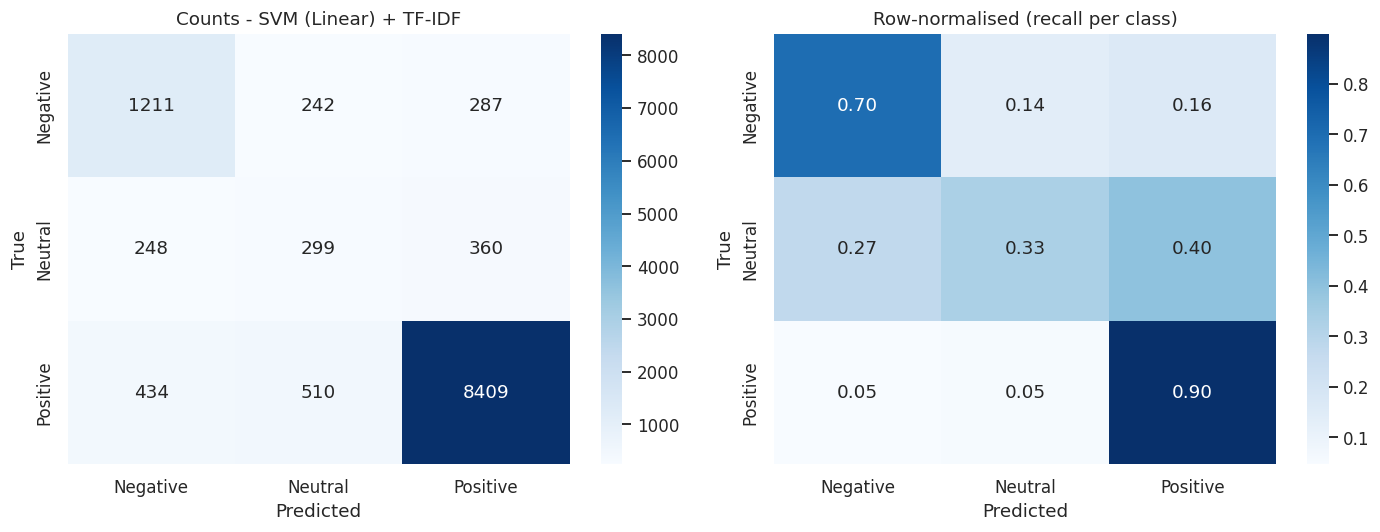

OBSERVATIONS
- Correct predictions: 9,919 of 12,000 (82.7%).
- Most common mistake: true 'Positive' predicted as 'Neutral' (510 reviews).


In [16]:
bk = (best["Vectorizer"], best["Model"])
cm_raw  = confusion_matrix(y_test, preds[bk], labels=labels)
cm_norm = confusion_matrix(y_test, preds[bk], labels=labels, normalize="true")
lab = [str(l) for l in labels]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm_raw, annot=True, fmt="d", cmap="Blues", xticklabels=lab, yticklabels=lab, ax=axes[0])
axes[0].set(title=f"Counts - {bk[1]} + {bk[0]}", xlabel="Predicted", ylabel="True")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=lab, yticklabels=lab, ax=axes[1])
axes[1].set(title="Row-normalised (recall per class)", xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.show()

errors = cm_raw.copy(); np.fill_diagonal(errors, 0)
i, j = np.unravel_index(errors.argmax(), errors.shape)
print("OBSERVATIONS")
print(f"- Correct predictions: {np.trace(cm_raw):,} of {cm_raw.sum():,} ({np.trace(cm_raw)/cm_raw.sum():.1%}).")
print(f"- Most common mistake: true '{lab[i]}' predicted as '{lab[j]}' ({errors[i, j]:,} reviews).")

### 6.7 Classification reports (best vectoriser per model)

In [17]:
for m in model_order:
    print("=" * 62)
    print(f"{m}  +  {best_vec[m]}")
    print("=" * 62)
    print(reports[(best_vec[m], m)])

SVM (Linear)  +  TF-IDF
              precision    recall  f1-score   support

    Negative       0.64      0.70      0.67      1740
     Neutral       0.28      0.33      0.31       907
    Positive       0.93      0.90      0.91      9353

    accuracy                           0.83     12000
   macro avg       0.62      0.64      0.63     12000
weighted avg       0.84      0.83      0.83     12000

Logistic Regression  +  TF-IDF
              precision    recall  f1-score   support

    Negative       0.60      0.72      0.66      1740
     Neutral       0.23      0.48      0.31       907
    Positive       0.96      0.82      0.88      9353

    accuracy                           0.78     12000
   macro avg       0.60      0.67      0.62     12000
weighted avg       0.85      0.78      0.81     12000

Naive Bayes  +  BoW
              precision    recall  f1-score   support

    Negative       0.60      0.67      0.63      1740
     Neutral       0.26      0.38      0.31       907


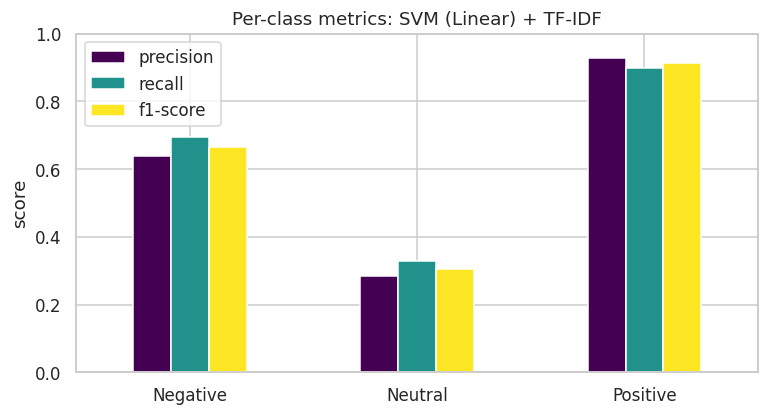

OBSERVATIONS
- Best class: 'Positive' (F1 0.91); weakest class: 'Neutral' (F1 0.31, only 907 test reviews).
- Classes with fewer examples score lower, which is why macro-F1 (equal weight per class) is lower than weighted-F1.


In [18]:
rep = classification_report(y_test, preds[bk], labels=labels, target_names=lab, output_dict=True, zero_division=0)
per_class = pd.DataFrame(rep).T.loc[lab, ["precision", "recall", "f1-score", "support"]]
per_class[["precision", "recall", "f1-score"]].plot(kind="bar", figsize=(8, 4), rot=0, colormap="viridis")
plt.title(f"Per-class metrics: {bk[1]} + {bk[0]}"); plt.ylim(0, 1); plt.ylabel("score"); plt.show()

print("OBSERVATIONS")
weak = per_class["f1-score"].idxmin(); strong = per_class["f1-score"].idxmax()
print(f"- Best class: '{strong}' (F1 {per_class.loc[strong, 'f1-score']:.2f}); weakest class: '{weak}' (F1 {per_class.loc[weak, 'f1-score']:.2f}, "
      f"only {int(per_class.loc[weak, 'support']):,} test reviews).")
print("- Classes with fewer examples score lower, which is why macro-F1 (equal weight per class) is lower than weighted-F1.")

## 7. Hyper-parameter Tuning (Logistic Regression)
Logistic Regression is a strong, fast and interpretable text baseline, so it is the model worth tuning.
`C` controls regularisation: small `C` = simpler model, large `C` = fits the training data more closely.
Search uses 3-fold cross-validation on the **training set only** and optimises macro-F1.

In [19]:
if RUN_TUNING:
    grid = GridSearchCV(
        LogisticRegression(max_iter=1000, class_weight="balanced"),
        param_grid={"C": [0.1, 0.5, 1, 5, 10]},
        scoring="f1_macro", cv=3, n_jobs=-1)
    t0 = time.time()
    grid.fit(Xtr["TF-IDF"], y_train)
    tune_time = time.time() - t0

    cv = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score"]]
    display(cv)
    print(f"Best C = {grid.best_params_['C']}   (CV macro-F1 = {grid.best_score_:.4f}, search took {tune_time:.0f}s)")

    evaluate("TF-IDF", "Logistic Regression (tuned)", grid.best_estimator_, tune_time)
    t = pd.DataFrame(records)
    untuned = t[(t.Model == "Logistic Regression") & (t.Vectorizer == "TF-IDF")]["F1 (macro)"].iloc[0]
    tuned = t[t.Model == "Logistic Regression (tuned)"]["F1 (macro)"].iloc[0]

    print("\nOBSERVATIONS")
    print(f"- Test macro-F1: default = {untuned:.4f}, tuned = {tuned:.4f}  (change {tuned - untuned:+.4f}).")
    print("- Gains from tuning are usually small for a well-set-up linear model; most improvement comes from better features")
    print("  (n-grams, vocabulary size) or more data rather than from tweaking C.")
else:
    print("Tuning skipped (RUN_TUNING = False).")

,param_C,mean_test_score,std_test_score
0,0.1000,0.6118,0.0040
1,0.5000,0.6194,0.0029
2,1.0000,0.6186,0.0019
3,5.0000,0.6076,0.0042
4,10.0000,0.5991,0.0044


Best C = 0.5   (CV macro-F1 = 0.6194, search took 19s)



OBSERVATIONS
- Test macro-F1: default = 0.6163, tuned = 0.6186  (change +0.0023).
- Gains from tuning are usually small for a well-set-up linear model; most improvement comes from better features
  (n-grams, vocabulary size) or more data rather than from tweaking C.


## 8. Final Ranking

In [20]:
final = pd.DataFrame(records).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
final.index += 1
display(final[["Model", "Vectorizer", "Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "Train time (s)"]])

champ = final.iloc[0]
print(f"CHAMPION: {champ['Model']} + {champ['Vectorizer']}  "
      f"(accuracy {champ['Accuracy']:.3f}, macro-F1 {champ['F1 (macro)']:.3f})")

,Model,Vectorizer,Accuracy,Precision (macro),Recall (macro),F1 (macro),Train time (s)
1,SVM (Linear),TF-IDF,0.8266,0.6176,0.6416,0.6286,1.1618
2,Logistic Regression (tuned),TF-IDF,0.7763,0.5981,0.6806,0.6186,19.4524
3,Logistic Regression,TF-IDF,0.7788,0.5962,0.6739,0.6163,1.1493
4,Naive Bayes,BoW,0.8040,0.5980,0.6403,0.6148,0.0956
5,SVM (Linear),BoW,0.8152,0.5990,0.6183,0.6078,15.6388
6,Logistic Regression,BoW,0.7727,0.5695,0.6279,0.5875,3.9624
7,Random Forest,BoW,0.8352,0.6385,0.5597,0.5740,75.7986
8,Random Forest,TF-IDF,0.8341,0.6468,0.5233,0.5436,73.8901
9,KNN,BoW,0.7586,0.4845,0.4776,0.4778,0.0738
10,KNN,TF-IDF,0.7933,0.5375,0.4518,0.4686,0.0807


CHAMPION: SVM (Linear) + TF-IDF  (accuracy 0.827, macro-F1 0.629)


## 9. Interpreting the Model – Most Predictive Words
For linear models we can read the learned weights: the larger a word's coefficient for a class, the more it pushes a
review toward that class. This works for Logistic Regression and Linear SVM (not for KNN or tree ensembles).

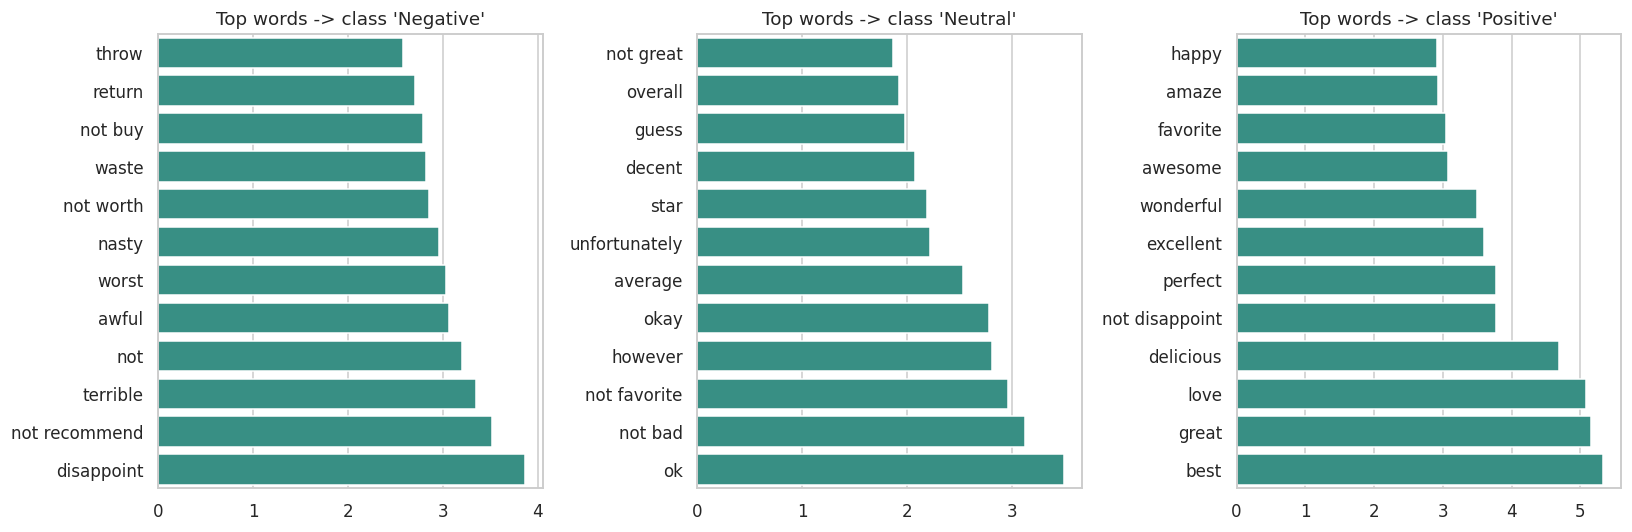

OBSERVATIONS
- 'Negative': disappoint, not recommend, terrible, not, awful, worst, nasty, not worth
- 'Neutral': ok, not bad, not favorite, however, okay, average, unfortunately, star
- 'Positive': best, great, love, delicious, not disappoint, perfect, excellent, wonderful
- Bigrams such as negated phrases appear among the strongest features, confirming that keeping 'not' in Sprint 1
  and using n-grams gives the model information that single words would miss.


In [21]:
lin_key = ("TF-IDF", "Logistic Regression (tuned)") if ("TF-IDF", "Logistic Regression (tuned)") in fitted \
          else ("TF-IDF", "Logistic Regression")
lr = fitted[lin_key]
feat = np.array(vectorizers["TF-IDF"].get_feature_names_out())
classes = list(lr.classes_)
coefs = lr.coef_ if len(classes) > 2 else np.vstack([-lr.coef_[0], lr.coef_[0]])

fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 5), squeeze=False)
for ax, cls, w in zip(axes[0], classes, coefs):
    idx = np.argsort(w)[-12:]
    sns.barplot(x=w[idx], y=feat[idx], color="#2a9d8f", ax=ax)
    ax.set_title(f"Top words -> class '{cls}'")
plt.tight_layout(); plt.show()

print("OBSERVATIONS")
for cls, w in zip(classes, coefs):
    print(f"- '{cls}': " + ", ".join(feat[np.argsort(w)[-8:][::-1]]))
print("- Bigrams such as negated phrases appear among the strongest features, confirming that keeping 'not' in Sprint 1")
print("  and using n-grams gives the model information that single words would miss.")

## 10. Save the Best Model & Predict on New Reviews

In [22]:
champ_key = (champ["Vectorizer"], champ["Model"])
joblib.dump({"vectorizer": vectorizers[champ_key[0]], "model": fitted[champ_key],
             "labels": labels, "target": TARGET}, "best_model.joblib")
print(f"Saved {champ_key[1]} + {champ_key[0]} -> best_model.joblib")

Saved SVM (Linear) + TF-IDF -> best_model.joblib


In [23]:
# New text must go through the SAME preprocessing used in Sprint 1
import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from functools import lru_cache

STOPWORDS = (set(stopwords.words("english")) - {"not", "no", "nor"}) | {"br"}
_lem = WordNetLemmatizer()
URL_RE, HTML_RE, NEG_RE, NONALPHA = (re.compile(r"(https?://\S+|www\.\S+)"), re.compile(r"<[^>]+>"),
                                     re.compile(r"n't\b"), re.compile(r"[^a-z\s]"))
IRREGULAR = {"won't": "will not", "can't": "can not", "shan't": "shall not", "ain't": "is not", "cannot": "can not"}

@lru_cache(maxsize=None)
def lemmatize(w):
    return _lem.lemmatize(_lem.lemmatize(w, pos="v"), pos="n")

def preprocess(text):
    text = html.unescape(str(text)).lower().replace("\u2019", "'")
    text = HTML_RE.sub(" ", URL_RE.sub(" ", text))
    for k, v in IRREGULAR.items():
        text = text.replace(k, v)
    text = NONALPHA.sub(" ", NEG_RE.sub(" not", text))
    return " ".join(lemmatize(t) for t in text.split() if t not in STOPWORDS and len(t) > 1)

bundle = joblib.load("best_model.joblib")

def predict_review(text):
    vec = bundle["vectorizer"].transform([preprocess(text)])
    return bundle["model"].predict(vec)[0]

examples = [
    "Absolutely love this coffee, rich flavor and arrives fresh. Will buy again!",
    "Terrible. The taste was awful and it arrived stale. Waste of money.",
    "It's okay, nothing special, but not bad for the price.",
    "I would not recommend this, not worth it at all.",
]
for e in examples:
    print(f"{predict_review(e):>9}  <-  {e}")

 Positive  <-  Absolutely love this coffee, rich flavor and arrives fresh. Will buy again!
 Negative  <-  Terrible. The taste was awful and it arrived stale. Waste of money.
  Neutral  <-  It's okay, nothing special, but not bad for the price.
 Negative  <-  I would not recommend this, not worth it at all.


## 11. Conclusions

*(Figures below are from the run saved in this notebook, a 60,000-review stratified sample with `TARGET="Sentiment"`; a re-run may differ slightly.)*

1. **Linear SVM + TF-IDF was the best model** (macro-F1 ≈ 0.63, accuracy ≈ 0.83), with Logistic Regression + TF-IDF close behind
   (≈ 0.62). Both train in seconds and are interpretable. Tuning Logistic Regression's `C` added only ≈ 0.002 macro-F1, so the
   model is limited by the features and the task, not the settings.
2. **Accuracy is misleading.** 78% of reviews are positive, so Random Forest reaches the highest accuracy (≈ 0.83) yet finds only
   ≈ 13% of neutral reviews (macro-F1 ≈ 0.57); Naive Bayes + TF-IDF has 0.83 accuracy but only 0.47 macro-F1.
3. **The neutral (3★) class is the real bottleneck**: F1 ≈ 0.31 for the best model. Neutral reviews mix praise and complaints, and the
   top "neutral" terms are hedges (*ok, not bad, average, however*). Running with `TARGET="Binary"` removes this problem.
4. **KNN and Decision Tree were weakest**; KNN is also slow at prediction time and Random Forest is slow to train (≈ 75 s here),
   with no benefit over linear models on sparse, high-dimensional text.
5. **Preprocessing choices mattered**: keeping negations and adding bigrams lets the model learn phrases such as "not recommend",
   "not worth" and "not disappoint" (all among the strongest features in section 9).

### Limitations & next steps
- Models were trained on a stratified **sample**; set `SAMPLE_SIZE = None` for the final numbers.
- Reviews from the same user may appear in both train and test; a user-grouped split would give a stricter estimate.
- Try `TARGET = "Binary"` (positive vs negative) for the cleanest signal, or `TARGET = "Score"` for exact star prediction.
- Further ideas: character n-grams, word embeddings (Word2Vec / GloVe), or a fine-tuned transformer such as DistilBERT.